In [1]:
library(lme4)
library(rstanarm)
library(emmeans)
library(dplyr)

Loading required package: Matrix

Loading required package: Rcpp

This is rstanarm version 2.32.2

- See https://mc-stan.org/rstanarm/articles/priors for changes to default priors!

- Default priors may change, so it's safest to specify priors, even if equivalent to the defaults.

- For execution on a local, multicore CPU with excess RAM we recommend calling

  options(mc.cores = parallel::detectCores())

Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [3]:
df <- read.csv("../processed_data/acceptance_data_for_logistic_regression.csv") %>%
  mutate(
    # Convert categorical variables to factors
    tone = as.factor(tone),
    lang = as.factor(lang),
    word = as.factor(word),
    participant = as.factor(participant),
    word_log_freq_z = as.numeric(log(word_freq)),
    
    acceptance = as.integer(as.logical(acceptance)) 
  )

In [4]:
# z-score word_log_freq within each language
df <- df %>%
  group_by(lang) %>%
  mutate(word_log_freq_z = scale(word_log_freq_z)) %>%
  ungroup()

NOTE: Results may be misleading due to involvement in interactions



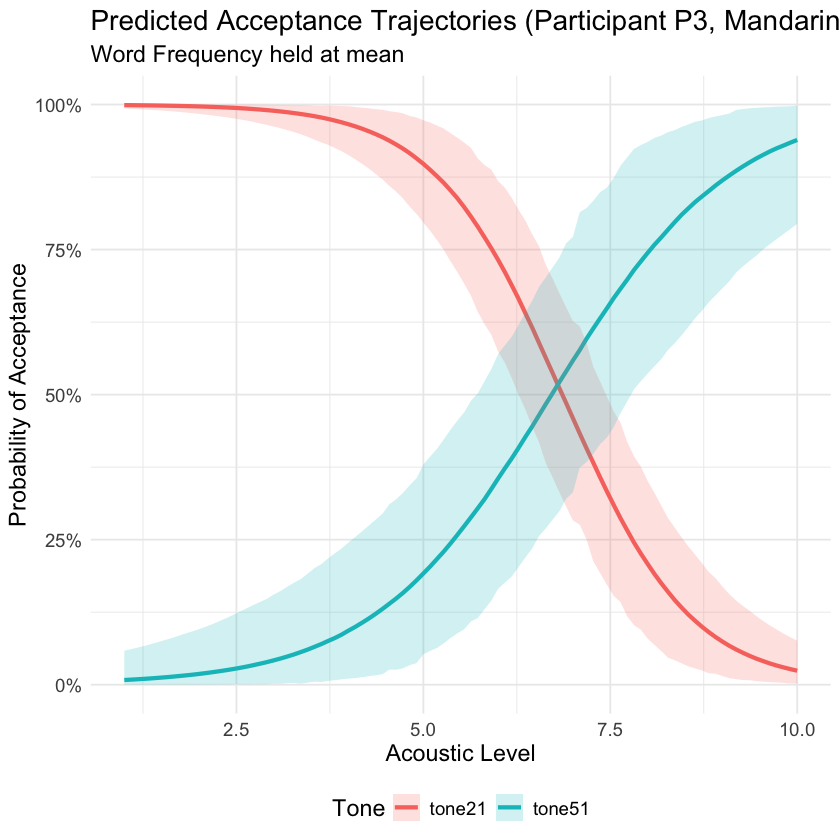

In [ ]:
library(emmeans)
library(ggplot2)

sub_df <- df %>% 
      filter(lang == "man", participant == "P3")

model <- stan_glm(acceptance ~ level * tone * word_log_freq_z, 
                        data = sub_df, 
                        family = binomial(link = "logit"),
                        refresh = 0)
                        
# 1. Create a smooth sequence of 'level' values for the x-axis
# We use 100 points between the minimum and maximum level in your data
level_sequence <- seq(min(sub_df$level), max(sub_df$level), length.out = 100)

# 2. Extract the predicted probabilities
# 'at' tells it exactly which x-values to calculate for
# 'type = "response"' converts the output from log-odds to 0-1 probabilities
predicted_grid <- emmeans(model, ~ level * tone, 
                          at = list(level = level_sequence), 
                          type = "response")

# Convert the emmeans object into a standard dataframe for plotting
plot_df <- as.data.frame(predicted_grid)

# 3. Plot the trajectories
# Note: Because you used stan_glm (Bayesian), emmeans names the confidence 
# interval columns 'lower.HPD' and 'upper.HPD' (Highest Posterior Density).
ggplot(plot_df, aes(x = level, y = prob, color = tone, fill = tone)) +
  
  # Add the solid trajectory lines
  geom_line(linewidth = 1.2) +
  
  # Add the 95% credible intervals (the shaded uncertainty region)
  geom_ribbon(aes(ymin = lower.HPD, ymax = upper.HPD), alpha = 0.2, color = NA) +
  
  # Format the y-axis as percentages
  scale_y_continuous(limits = c(0, 1), labels = scales::percent) +
  
  # Add clear labels
  labs(title = "Predicted Acceptance Trajectories (Participant P3, Mandarin)",
       subtitle = "Word Frequency held at mean",
       x = "Acoustic Level",
       y = "Probability of Acceptance",
       color = "Tone",
       fill = "Tone") +
  
  # Use a clean, modern theme
  theme_minimal() +
  theme(text = element_text(size = 14),
        legend.position = "bottom")

# save plot as csv
write.csv(plot_df, "predicted_trajectories_P3_mandarin.csv", row.names = FALSE)

NOTE: Results may be misleading due to involvement in interactions



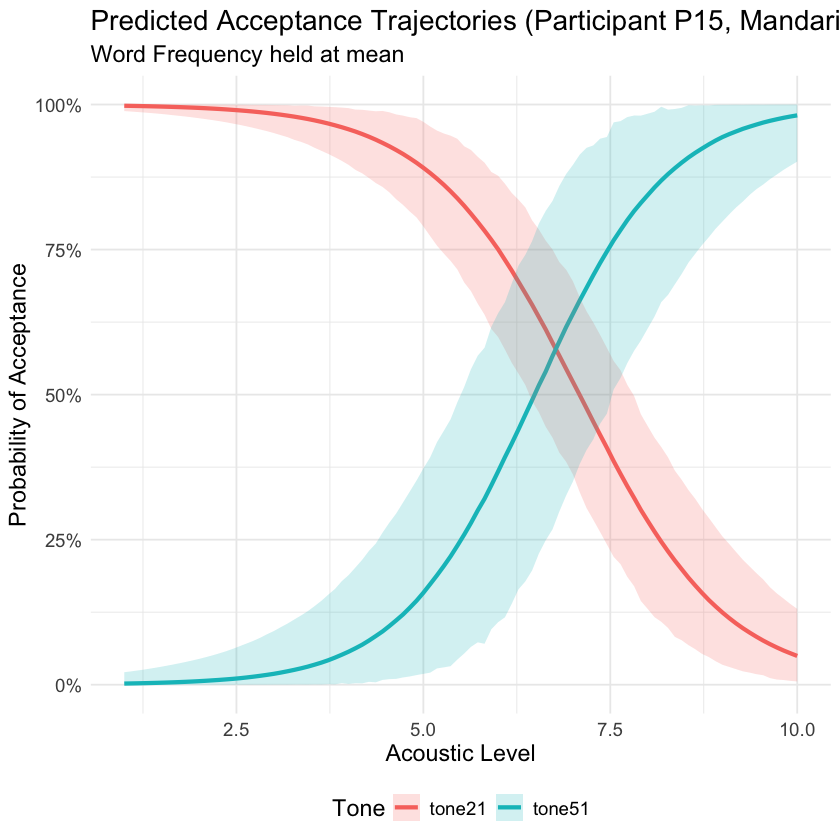

In [7]:
library(emmeans)
library(ggplot2)

sub_df <- df %>% 
      filter(lang == "man", participant == "P15")

model <- stan_glm(acceptance ~ level * tone * word_log_freq_z, 
                        data = sub_df, 
                        family = binomial(link = "logit"),
                        refresh = 0)

# 1. Create a smooth sequence of 'level' values for the x-axis
# We use 100 points between the minimum and maximum level in your data
level_sequence <- seq(min(sub_df$level), max(sub_df$level), length.out = 100)

# 2. Extract the predicted probabilities
# 'at' tells it exactly which x-values to calculate for
# 'type = "response"' converts the output from log-odds to 0-1 probabilities
predicted_grid <- emmeans(model, ~ level * tone, 
                          at = list(level = level_sequence), 
                          type = "response")

# Convert the emmeans object into a standard dataframe for plotting
plot_df <- as.data.frame(predicted_grid)

# 3. Plot the trajectories
# Note: Because you used stan_glm (Bayesian), emmeans names the confidence 
# interval columns 'lower.HPD' and 'upper.HPD' (Highest Posterior Density).
ggplot(plot_df, aes(x = level, y = prob, color = tone, fill = tone)) +
  
  # Add the solid trajectory lines
  geom_line(linewidth = 1.2) +
  
  # Add the 95% credible intervals (the shaded uncertainty region)
  geom_ribbon(aes(ymin = lower.HPD, ymax = upper.HPD), alpha = 0.2, color = NA) +
  
  # Format the y-axis as percentages
  scale_y_continuous(limits = c(0, 1), labels = scales::percent) +
  
  # Add clear labels
  labs(title = "Predicted Acceptance Trajectories (Participant P15, Mandarin)",
       subtitle = "Word Frequency held at mean",
       x = "Acoustic Level",
       y = "Probability of Acceptance",
       color = "Tone",
       fill = "Tone") +
  
  # Use a clean, modern theme
  theme_minimal() +
  theme(text = element_text(size = 14),
        legend.position = "bottom")

# save plot as csv
write.csv(plot_df, "predicted_trajectories_P15_mandarin.csv", row.names = FALSE)